In [1]:
#Library
import numpy as np
import pandas as pd
import gym
from gym import spaces
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv
import matplotlib.pyplot as plt

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


In [2]:
from pathlib import Path
#Load dataset
df = pd.read_csv(Path.cwd().parent / "data" / "aapl_1984_2025.csv")
df["Date"] = pd.to_datetime(df["Date"])
df = df.sort_values("Date")
df.head()

,Date,Open,High,Low,Close,Volume
0,1984-09-07,0.099824,0.101049,0.098619,0.099824,9.859472e+07
1,1984-09-10,0.099824,0.100130,0.097424,0.099232,7.652559e+07
2,1984-09-11,0.100130,0.102846,0.100130,0.101049,1.804519e+08
3,1984-09-12,0.101049,0.101641,0.098007,0.098007,1.576401e+08
4,1984-09-13,0.103460,0.103754,0.103460,0.103460,2.455186e+08


In [3]:
#Enviroment dan model RL
class TradingEnv(gym.Env):
    def __init__(self, df, window_size=10, initial_balance=10000):
        super(TradingEnv, self).__init__() # inisialisasi class parent
        self.df = df # Data historis harga saham
        self.window_size = window_size # Jumlah langkah waktu dalam 1 observasi
        self.initial_balance = initial_balance # Saldo awal
        self.action_space = spaces.Discrete(3)  # 0: Hold, 1: Buy, 2: Sell
        self.observation_space = spaces.Box(low=0, high=np.inf, shape=(window_size, 5), dtype=np.float32) # Ruang observasi: Matriks dengan shape (window_size, 5) untuk Open, High, Low, Close, Volume
        self.reset() # inisialisasi ulang state
        
    
# Fungsi reset akan dipanggil saat episode baru dimulai
    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.balance = self.initial_balance # Reset saldo
        self.stock_held = 0  # Jumlah saham yang dimiliki
        self.total_asset = self.initial_balance # Total kekayaan saat ini
        self.trades = [] # Daftar transaksi (Buy/Sell)
        self.current_step = self.window_size # Awal langkah saat window_size sudah bisa diobservasi
        return self._next_observation(), {} # Mengembalikan observasi awal
    
# Mendapatkan observasi berupa data historis dalam window_size
    def _next_observation(self):
        obs = self.df.iloc[self.current_step - self.window_size:self.current_step] # Ambil data window_size terakhir
        obs = obs[['Open', 'High', 'Low', 'Close', 'Volume']].values # Ambil hanya kolom yang diperlukan
        return obs.astype(np.float32) # Konversi ke tipe float32
    
# Fungsi step akan dijalankan setiap kali agent memilih aksi
    def step(self, action):
        current_price = self.df.iloc[self.current_step]['Close'] # Harga saat ini berdasarkan kolom 'Close'

# Jika aksi adalah Buy dan saldo cukup
        if action == 1 and self.balance >= current_price:
            self.stock_held += 1 # Tambah saham yang dimiliki
            self.balance -= current_price # Kurangi saldo
            self.trades.append(('Buy', current_price)) # Catat transaksi

# Jika aksi adalah Sell dan ada saham yang dimiliki
        elif action == 2 and self.stock_held > 0:
            self.stock_held -= 1 # Kurangi saham
            self.balance += current_price # Tambah saldo
            self.trades.append(('Sell', current_price)) # Catat transaksi

        self.current_step += 1 # Pindah ke langkah berikutnya
        done = self.current_step >= len(self.df) - 1 # Cek apakah episode selesai (sampai akhir data)
        self.total_asset = self.balance + self.stock_held * current_price # Hitung total aset saat ini
        reward = self.total_asset - self.initial_balance # Reward = perubahan total aset dibandingkan modal awal

# Observasi berikutnya, atau nol jika episode selesai
        obs = self._next_observation() if not done else np.zeros((self.window_size, 5), dtype=np.float32)
        return obs, reward, done, False, {} # Return format: (observasi, reward, selesai, truncated, info tambahan)

# Fungsi render untuk menampilkan informasi saat ini
    def render(self):
        print(f'Step: {self.current_step} | Balance: ${self.balance:.2f} | Stock Held: {self.stock_held} | Asset: ${self.total_asset:.2f}')
        if self.trades:
            print(f"Last Trades: {self.trades[-5:]}") # Menampilkan 5 transaksi terakhir

In [4]:
#Traininh model
env = DummyVecEnv([lambda: TradingEnv(df)])
model = PPO("MlpPolicy", env, verbose=1)
model.learn(total_timesteps=10000) # Melatih model dengan total 10.000 langkah interaksi
model.save("ppo_trading_model") # Menyimpan model hasil training ke file dengan nama "ppo_trading_model"

<home>\Desktop\Main\UNIV\.venv-tf312\Lib\site-packages\stable_baselines3\common\vec_env\patch_gym.py:49: UserWarning: You provided an OpenAI Gym environment. We strongly recommend transitioning to Gymnasium environments. Stable-Baselines3 is automatically wrapping your environments in a compatibility layer, which could potentially cause issues.
  warnings.warn(


Using cpu device


-----------------------------
| time/              |      |
|    fps             | 1534 |
|    iterations      | 1    |
|    time_elapsed    | 1    |
|    total_timesteps | 2048 |
-----------------------------


------------------------------------------
| time/                   |              |
|    fps                  | 1220         |
|    iterations           | 2            |
|    time_elapsed         | 3            |
|    total_timesteps      | 4096         |
| train/                  |              |
|    approx_kl            | 0.0075462153 |
|    clip_fraction        | 0.0279       |
|    clip_range           | 0.2          |
|    entropy_loss         | -1.09        |
|    explained_variance   | -0.000353    |
|    learning_rate        | 0.0003       |
|    loss                 | 2.13e+03     |
|    n_updates            | 10           |
|    policy_gradient_loss | -0.00571     |
|    value_loss           | 4.49e+03     |
------------------------------------------


-----------------------------------------
| time/                   |             |
|    fps                  | 1180        |
|    iterations           | 3           |
|    time_elapsed         | 5           |
|    total_timesteps      | 6144        |
| train/                  |             |
|    approx_kl            | 0.009779137 |
|    clip_fraction        | 0.0214      |
|    clip_range           | 0.2         |
|    entropy_loss         | -1.08       |
|    explained_variance   | 0.000688    |
|    learning_rate        | 0.0003      |
|    loss                 | 1.67e+04    |
|    n_updates            | 20          |
|    policy_gradient_loss | -0.00488    |
|    value_loss           | 3.66e+04    |
-----------------------------------------


------------------------------------------
| time/                   |              |
|    fps                  | 1139         |
|    iterations           | 4            |
|    time_elapsed         | 7            |
|    total_timesteps      | 8192         |
| train/                  |              |
|    approx_kl            | 0.0014167568 |
|    clip_fraction        | 0            |
|    clip_range           | 0.2          |
|    entropy_loss         | -1.07        |
|    explained_variance   | 0.0006       |
|    learning_rate        | 0.0003       |
|    loss                 | 1.11e+05     |
|    n_updates            | 30           |
|    policy_gradient_loss | -0.00111     |
|    value_loss           | 2.29e+05     |
------------------------------------------


-------------------------------------------
| time/                   |               |
|    fps                  | 1121          |
|    iterations           | 5             |
|    time_elapsed         | 9             |
|    total_timesteps      | 10240         |
| train/                  |               |
|    approx_kl            | 0.00052099716 |
|    clip_fraction        | 0             |
|    clip_range           | 0.2           |
|    entropy_loss         | -1.06         |
|    explained_variance   | 6.32e-06      |
|    learning_rate        | 0.0003        |
|    loss                 | 2.8e+05       |
|    n_updates            | 40            |
|    policy_gradient_loss | -0.000514     |
|    value_loss           | 5.47e+05      |
-------------------------------------------


In [5]:
#Model testing
env_single = TradingEnv(df)
obs, _ = env_single.reset() # Reset environment dan ambil observasi awal
done = False # Menandakan apakah episode selesai
step_count = 0 # Menghitung jumlah langkah
total_rewards = 0 # Akumulasi reward selama episode
asset_values = [] # Menyimpan nilai total aset di setiap langkah
while not done: # Loop sampai episode selesai
    action, _states = model.predict(obs) # Model memprediksi aksi berdasarkan observasi saat ini
    obs, reward, done, _, _ = env_single.step(action) # Eksekusi aksi di environment dan ambil hasilnya
    total_rewards += reward # Tambahkan reward ke total
    asset_values.append(env_single.total_asset) # Simpan total aset saat ini untuk analisis atau visualisasi
    step_count += 1 # Tambahkan langkah
    if step_count % 1000 == 0 or done: # Tampilkan informasi tiap 1000 langkah atau saat episode selesai
        env_single.render()

Step: 1010 | Balance: $10000.75 | Stock Held: 0 | Asset: $10000.75
Last Trades: [('Sell', 0.316676), ('Buy', 0.308302), ('Buy', 0.308302), ('Sell', 0.300715), ('Sell', 0.29306)]


Step: 2010 | Balance: $10000.29 | Stock Held: 0 | Asset: $10000.29
Last Trades: [('Sell', 0.332627), ('Sell', 0.328103), ('Sell', 0.337437), ('Sell', 0.337437), ('Sell', 0.337437)]


Step: 3010 | Balance: $10000.18 | Stock Held: 0 | Asset: $10000.18
Last Trades: [('Buy', 0.136072), ('Sell', 0.157465), ('Buy', 0.156536), ('Sell', 0.152625), ('Sell', 0.154372)]


Step: 4010 | Balance: $9999.31 | Stock Held: 1 | Asset: $10000.14
Last Trades: [('Buy', 0.887815), ('Buy', 0.851963), ('Buy', 0.879619), ('Sell', 0.863224), ('Sell', 0.794383)]


Step: 5010 | Balance: $9999.57 | Stock Held: 1 | Asset: $10000.06
Last Trades: [('Buy', 0.490043), ('Sell', 0.490043), ('Buy', 0.439424), ('Buy', 0.446062), ('Sell', 0.496403)]


Step: 6010 | Balance: $10005.57 | Stock Held: 0 | Asset: $10005.57
Last Trades: [('Sell', 5.59921), ('Buy', 5.22547), ('Sell', 5.1985), ('Buy', 5.22527), ('Sell', 5.35021)]


Step: 7010 | Balance: $10002.91 | Stock Held: 1 | Asset: $10020.47
Last Trades: [('Buy', 17.2437), ('Sell', 17.227), ('Sell', 17.6664), ('Buy', 17.4204), ('Sell', 17.5559)]


Step: 8010 | Balance: $9997.19 | Stock Held: 2 | Asset: $10041.75
Last Trades: [('Buy', 22.903), ('Sell', 22.583), ('Sell', 22.4143), ('Buy', 22.8547), ('Buy', 22.6689)]


Step: 9010 | Balance: $9999.25 | Stock Held: 1 | Asset: $10080.09
Last Trades: [('Buy', 77.7691), ('Sell', 77.6141), ('Buy', 79.286), ('Sell', 78.6037), ('Buy', 80.8438)]


Step: 10010 | Balance: $9768.82 | Stock Held: 2 | Asset: $10148.36
Last Trades: [('Buy', 189.65), ('Sell', 190.679), ('Sell', 186.664), ('Buy', 189.76), ('Sell', 189.77)]
Step: 10170 | Balance: $10165.25 | Stock Held: 0 | Asset: $10165.25
Last Trades: [('Sell', 242.21), ('Sell', 242.7), ('Sell', 234.4), ('Buy', 237.87), ('Sell', 228.26)]


In [6]:
#Hasil model
print("\n=== TESTING SUMMARY ===") # Menampilkan ringkasan hasil pengujian model
print(f"Total Steps: {step_count}") # Menampilkan total langkah yang dilakukan selama episode
print(f"Initial Balance: ${env_single.initial_balance:.2f}") # Menampilkan saldo awal saat episode dimulai
print(f"Final Asset Value: ${env_single.total_asset:.2f}") # Menampilkan total nilai aset akhir (saldo + nilai saham yang dimiliki)
profit = env_single.total_asset - env_single.initial_balance # Menghitung profit sebagai selisih nilai aset akhir dan saldo awal
print(f"Profit: ${profit:.2f} ({profit / env_single.initial_balance * 100:.2f}%)") # Menampilkan profit dalam bentuk nominal dan persentase terhadap saldo awal


=== TESTING SUMMARY ===
Total Steps: 10160
Initial Balance: $10000.00
Final Asset Value: $10165.25
Profit: $165.25 (1.65%)


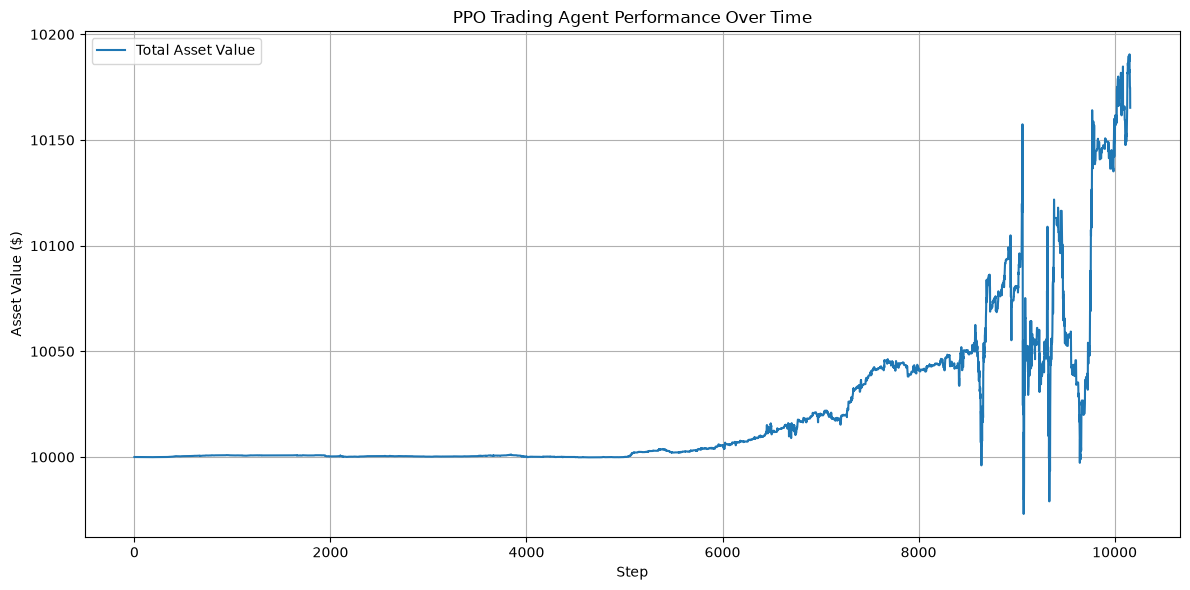

In [7]:
#Visualisasi
plt.figure(figsize=(12, 6))
plt.plot(asset_values, label="Total Asset Value")
plt.xlabel("Step")
plt.ylabel("Asset Value ($)")
plt.title("PPO Trading Agent Performance Over Time")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()